# 04. Precios de los 59 productos e índice por comercio

Bloque 4 del proyecto. Se usa el precio de cada uno de los 59 productos de la canasta básica de ACODECO en cada establecimiento para responder tres preguntas:

1. ¿Qué cadenas y tipos de tienda son más caros o más baratos? (índice de precio relativo)
2. ¿Cuánto cambió el precio de cada producto entre 2019, 2022 y 2026?
3. ¿Cuánto varía el precio de un mismo producto entre tiendas en septiembre de 2026?

Cortes: marzo–diciembre de 2019, enero–junio de 2022 y la 2.ª quincena de septiembre de 2026. La única entrada es `data/processed/precios_supermercados.csv`. El costo total de la canasta no se recalcula aquí (sumar 59 precios unitarios no tiene interpretación); se muestra el oficial de ACODECO solo como contexto.

## 1. Librerías, rutas y datos

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.axisbelow'] = True

# Azul = más barato o baja. Rojo = más caro o sube.
AZUL = '#257de0'
ROJO = '#ec4647'

raiz = Path('.') if Path('data/processed').exists() else Path('..')
figuras = raiz / 'outputs' / 'figures'
tablas = raiz / 'outputs' / 'tablas'
figuras.mkdir(parents=True, exist_ok=True)
tablas.mkdir(parents=True, exist_ok=True)

precios = pd.read_csv(raiz / 'data/processed/precios_supermercados.csv')
precios.head()

,fecha,anio,mes,quincena,producto,producto_estandar,medida,establecimiento,establecimiento_estandar,cadena,zona,precio,control_precio,fuente
0,2019-03-01,2019,3,NaN,Babilla (Carne de res de Primera) *,babilla (carne de res de primera),1 Kilogramos,CASA DE LA CARNE CANGREJO,CASA DE LA CARNE CANGREJO,NaN,sin_clasificar,NaN,True,acodeco_csv
1,2019-03-01,2019,3,NaN,Bistec de Cinta *,bistec de cinta,1 Kilogramos,CASA DE LA CARNE CANGREJO,CASA DE LA CARNE CANGREJO,NaN,sin_clasificar,NaN,True,acodeco_csv
2,2019-03-01,2019,3,NaN,Carne Molida de Primera *,carne molida de primera,1 Kilogramos,CASA DE LA CARNE CANGREJO,CASA DE LA CARNE CANGREJO,NaN,sin_clasificar,NaN,True,acodeco_csv
3,2019-03-01,2019,3,NaN,Carne para Sopa (Costilla) *,carne para sopa (costilla),1 Kilogramos,CASA DE LA CARNE CANGREJO,CASA DE LA CARNE CANGREJO,NaN,sin_clasificar,4.70,True,acodeco_csv
4,2019-03-01,2019,3,NaN,Puerco Liso *,puerco liso,1 Kilogramos,CASA DE LA CARNE CANGREJO,CASA DE LA CARNE CANGREJO,NaN,sin_clasificar,6.39,True,acodeco_csv


## 2. Cobertura por corte

Un precio vacío significa que la tienda no lo reportó; nunca se trata como cero.

In [2]:
cobertura = precios.groupby('anio').agg(
    meses=('mes', 'nunique'),
    nombres_de_tienda=('establecimiento_estandar', 'nunique'),
    registros=('precio', 'size'),
    con_precio=('precio', 'count'),
    productos=('producto_estandar', 'nunique'))
cobertura['con precio (%)'] = cobertura['con_precio'] / cobertura['registros'] * 100
cobertura.round(1)

,meses,nombres_de_tienda,registros,con_precio,productos,con precio (%)
anio,,,,,,
2019,10,95,52510,35585,59,67.8
2022,6,109,31624,21473,59,67.9
2026,1,82,5015,3771,59,75.2


## 3. Depuración (sin modificar el CSV)

Cinco ajustes, todos documentados y reversibles:

1. **Medida del aceite.** En los CSV de 2019 y 2022 la medida viene como `"1,42 Litros"` entre comillas; al separar por coma quedó `"1`. Es la misma presentación de 1.42 L, así que se corrige en vez de borrar el producto. *(Conviene corregirlo también en `src/io_acodeco.py`.)*
2. **Tiendas con el mismo nombre.** En el PDF de 2026, `EL MACHETAZO`, `SUPER 99` y `XTRA MARKET` aparecen dos veces: una en el recuadro de San Miguelito y otra fuera. Se distinguen agregando la zona al nombre, en lugar de excluirlas.
3. **Columnas de cadena que vienen de la tabla "en Rutas".** De esos seis duplicados, tres (`XTRA MARKET` y `SUPER 99` del recuadro San Miguelito, y `EL MACHETAZO` de Villa Zaita) están en la página 5 del PDF, que es la tabla de precios **en Rutas** (minisúper y abarroterías), no en las páginas de supermercados. Por ejemplo, el plátano a B/. 1.87 y el repollo a B/. 0.50 de `XTRA MARKET` están en esa página. Se marcan como grupo `cadena en rutas` para no mezclarlos con los supermercados de la cadena. *(Lo correcto es que `src/io_acodeco.py` guarde una columna con la tabla de origen: supermercados o rutas.)*
4. **Tipo de comercio.** Si la tienda no pertenece a una cadena, se usa su tipo (minisúper, abarrotería, frutería). `CASA DE LA CARNE` reporta entre 53 y 58 de los 59 productos (arroz, aceite, café, etc.), así que se trata como supermercado propio y no como carnicería. Lo que no encaja en nada queda como `sin cadena`.
5. **Precios atípicos.** Se excluye todo precio mayor que 4 veces, o menor que la cuarta parte, de la mediana del mismo producto en el mismo mes.

In [3]:
datos = precios.copy()

# 1. Medida del aceite cortada por la coma decimal.
datos['medida'] = datos['medida'].replace('"1', '1,42 Litros')

# 2. Nombre de tienda único: se agrega la zona solo donde el nombre se repite.
clave = ['fecha', 'establecimiento_estandar', 'producto_estandar']
repetido = datos.duplicated(subset=clave, keep=False)
ambiguo = datos.assign(r=repetido).groupby(['fecha', 'establecimiento_estandar'])['r'].transform('any')
datos['tienda'] = datos['establecimiento_estandar']
datos.loc[ambiguo, 'tienda'] = (datos.loc[ambiguo, 'establecimiento_estandar'] + ' ('
                                 + datos.loc[ambiguo, 'zona'].str.replace('_', ' ') + ')')
print('Tiendas renombradas con su zona:', sorted(datos.loc[ambiguo, 'tienda'].unique()))
print('Claves repetidas después del ajuste:', datos.duplicated(subset=['fecha', 'tienda', 'producto_estandar']).sum())

# 3. Las tres columnas de cadena que vienen de la tabla "en Rutas" (página 5 del PDF de 2026).
en_rutas = {'XTRA MARKET (san miguelito)': 'XTRA MARKET (en rutas, San Miguelito)',
            'SUPER 99 (san miguelito)': 'SUPER 99 (en rutas, San Miguelito)',
            'EL MACHETAZO (sin clasificar)': 'EL MACHETAZO (en rutas, Villa Zaita)'}
es_rutas = datos['tienda'].isin(list(en_rutas))
datos['tienda'] = datos['tienda'].replace(en_rutas)

# 4. Cadena o tipo de comercio.
datos['grupo'] = datos['cadena'].fillna('sin cadena')
datos.loc[datos['tienda'].str.startswith('CASA DE LA CARNE'), 'grupo'] = 'Casa de la Carne'
datos.loc[es_rutas, 'grupo'] = 'cadena en rutas'
print(datos[datos['anio'] == 2026].groupby('grupo')['tienda'].nunique().rename('tiendas 2026'))
print('Tiendas sin cadena ni tipo:', sorted(datos.loc[datos['grupo'] == 'sin cadena', 'tienda'].unique()))

# Control: cada producto debe tener una sola presentación en los tres cortes.
medidas = datos.groupby(['producto_estandar', 'anio'])['medida'].agg(lambda s: ' | '.join(sorted(s.dropna().unique())))
medidas = medidas.unstack()
print('Productos con más de una presentación:')
display(medidas[medidas.nunique(axis=1) > 1])
print('Filas sin medida (vienen vacías en las páginas "en rutas" del PDF de 2026):')
display(datos[datos['medida'].isna()].groupby(['anio', 'producto_estandar']).size())

Tiendas renombradas con su zona: ['EL MACHETAZO (san miguelito)', 'EL MACHETAZO (sin clasificar)', 'SUPER 99 (san miguelito)', 'SUPER 99 (sin clasificar)', 'XTRA MARKET (san miguelito)', 'XTRA MARKET (sin clasificar)']
Claves repetidas después del ajuste: 0
grupo
El Fuerte           3
Machetazo           6
Rey                 9
Riba Smith          2
Super 99           17
Xtra               14
abarrotería         8
cadena en rutas     3
frutería            1
minisúper          22
Name: tiendas 2026, dtype: int64
Tiendas sin cadena ni tipo: ['EL CANGREJO VIA ARGENTINA']
Productos con más de una presentación:


anio,2019,2022,2026
producto_estandar,,,


Filas sin medida (vienen vacías en las páginas "en rutas" del PDF de 2026):


anio  producto_estandar                
2026  leche en polvo entera instantánea    34
dtype: int64

In [4]:
# 5. Precios atípicos frente a la mediana del producto en el mismo mes.
con_precio = datos[datos['precio'] > 0].copy()
mediana_mes = con_precio.groupby(['fecha', 'producto_estandar'])['precio'].transform('median')
razon = con_precio['precio'] / mediana_mes
atipico = (razon > 4) | (razon < 0.25)

tabla_atipicos = con_precio[atipico][['fecha', 'producto_estandar', 'tienda', 'precio']].copy()
tabla_atipicos['mediana del mes'] = mediana_mes[atipico]
display(tabla_atipicos)

limpios = con_precio[~atipico].copy()
# Mediana del producto en el mes, ya sin atípicos: es la "tienda típica".
limpios['mediana_mes'] = limpios.groupby(['fecha', 'producto_estandar'])['precio'].transform('median')
print('Precios usados en el análisis:')
print(limpios.groupby('anio')['precio'].count())

,fecha,producto_estandar,tienda,precio,mediana del mes
39548,2019-10-01,hojuelas de maíz (corn flakes) cajeta,REY MILLA 8,0.58,2.65
39558,2019-10-01,papa nacional,REY MILLA 8,0.25,1.54
50236,2019-12-01,ñame diamante,MINISUPER CD,3.86,0.88
50238,2019-12-01,plátano verde,MINISUPER CD,1.54,0.35
88705,2026-09-01,plátano verde,"XTRA MARKET (en rutas, San Miguelito)",1.87,0.40
88720,2026-09-01,repollo verde,"XTRA MARKET (en rutas, San Miguelito)",0.50,2.75


Precios usados en el análisis:
anio
2019    35581
2022    21473
2026     3769
Name: precio, dtype: int64


## 4. Contexto: ¿cuánto cuesta la canasta oficial?

ACODECO publica cada mes el **costo total** de su canasta de 59 productos (precio promedio en supermercados × cantidad que consume una familia). La tabla responde: ¿cuánto costaba la canasta al mes en cada año y cuánto subió desde 2019?

- **Promedio enero–agosto:** se usan esos ocho meses porque son los que existen en los tres años (2026 llega hasta agosto).
- **Junio:** el mes que usa la diapositiva de canasta frente a salario. También se usa en la sección 7.

In [5]:
canasta = pd.read_csv(raiz / 'data/processed/costo_canasta_mensual.csv')
canasta = canasta[canasta['fuente'] == 'acodeco_historico']

# Promedio de enero a agosto de cada año.
promedio = canasta[canasta['mes'].between(1, 8)].groupby('anio')['costo_total'].mean()
# Costo de junio de cada año.
costo_junio = canasta[canasta['mes'] == 6].set_index('anio')['costo_total']

costo_oficial = pd.DataFrame({
    'Costo mensual promedio ene–ago (B/.)': promedio,
    'Aumento desde 2019 (B/.)': promedio - promedio[2019],
    'Aumento desde 2019 (%)': (promedio / promedio[2019] - 1) * 100,
    'Costo de junio (B/.)': costo_junio})
costo_oficial.index.name = 'Año'

print('Cómo leerla: en 2026 la canasta cuesta en promedio B/. %.2f al mes,' % promedio[2026],
      'B/. %.2f más que en 2019 (%+.1f %%).' % (promedio[2026] - promedio[2019], (promedio[2026] / promedio[2019] - 1) * 100))
costo_oficial.round(2)

Cómo leerla: en 2026 la canasta cuesta en promedio B/. 303.86 al mes, B/. 41.44 más que en 2019 (+15.8 %).


,Costo mensual promedio ene–ago (B/.),Aumento desde 2019 (B/.),Aumento desde 2019 (%),Costo de junio (B/.)
Año,,,,
2019,262.42,0.00,0.00,260.64
2022,281.05,18.63,7.10,285.92
2026,303.86,41.44,15.79,303.45


## 5. ¿Cuánto cambió el precio de cada producto?

Para cada producto se toma el precio **mediano** entre todas las tiendas en cada corte: el precio del medio (la mitad de las tiendas cobra menos y la otra mitad más). Luego se calcula cuánto cambió en porcentaje.

In [6]:
# Precio mediano de cada producto en cada corte.
productos = limpios.pivot_table(index='producto_estandar', columns='anio', values='precio', aggfunc='median')
productos.columns = ['Precio 2019 (B/.)', 'Precio 2022 (B/.)', 'Precio 2026 (B/.)']

# Cambio porcentual entre cortes.
productos['Cambio 2019→2022 (%)'] = (productos['Precio 2022 (B/.)'] / productos['Precio 2019 (B/.)'] - 1) * 100
productos['Cambio 2022→2026 (%)'] = (productos['Precio 2026 (B/.)'] / productos['Precio 2022 (B/.)'] - 1) * 100
productos['Cambio 2019→2026 (%)'] = (productos['Precio 2026 (B/.)'] / productos['Precio 2019 (B/.)'] - 1) * 100
productos = productos.sort_values('Cambio 2019→2026 (%)', ascending=False)
productos.round(2).to_csv(tablas / 'supermercados_59_productos.csv')

cambio = productos['Cambio 2019→2026 (%)']
print('De los 59 productos:', (cambio > 0).sum(), 'suben,', (cambio < 0).sum(), 'bajan y', (cambio == 0).sum(), 'no cambian.')
print('Cambio típico (mediana) 2019→2026: %.1f %%' % cambio.median())
with pd.option_context('display.max_rows', None):
    display(productos.round(2))

De los 59 productos: 46 suben, 10 bajan y 3 no cambian.
Cambio típico (mediana) 2019→2026: 12.4 %


,Precio 2019 (B/.),Precio 2022 (B/.),Precio 2026 (B/.),Cambio 2019→2022 (%),Cambio 2022→2026 (%),Cambio 2019→2026 (%)
producto_estandar,,,,,,
ñame diamante,0.88,0.85,2.48,-3.41,191.76,181.82
arroz de primera,0.88,0.88,1.54,0.00,75.00,75.00
cebolla amarilla,1.76,1.65,2.95,-6.25,78.79,67.61
margarina en barra,2.84,3.28,4.41,15.49,34.45,55.28
ají dulce y/o picoloro,2.26,2.20,3.40,-2.65,54.32,50.22
pescado corvina,7.70,9.56,11.47,24.16,19.98,48.96
yuca,0.72,0.83,1.06,15.28,27.71,47.22
repollo verde,1.98,2.20,2.75,11.11,25.00,38.89
azúcar morena,1.21,1.50,1.63,23.97,8.67,34.71


### 5.1. ¿El resultado es confiable?

Dos comprobaciones. Si dan un número parecido al de arriba, el resultado no depende de estos problemas:

1. Las tiendas no son las mismas en cada corte. Se repite el cálculo solo con las tiendas que aparecen en los tres.
2. 2019 son diez meses y 2026 una quincena, y las frutas y verduras cambian según el mes. Se compara septiembre de 2019 con septiembre de 2026.

In [7]:
# Comprobación 1: solo tiendas que aparecen en los tres cortes.
cortes_por_tienda = limpios.groupby('tienda')['anio'].nunique()
mismas_tiendas = cortes_por_tienda[cortes_por_tienda == 3].index
solo_mismas = limpios[limpios['tienda'].isin(mismas_tiendas)]
precio_mismas = solo_mismas.pivot_table(index='producto_estandar', columns='anio', values='precio', aggfunc='median')
cambio_mismas = (precio_mismas[2026] / precio_mismas[2019] - 1) * 100

# Comprobación 2: septiembre contra septiembre.
solo_sep = limpios[limpios['mes'] == 9]
precio_sep = solo_sep.pivot_table(index='producto_estandar', columns='anio', values='precio', aggfunc='median')
cambio_sep = (precio_sep[2026] / precio_sep[2019] - 1) * 100

comprobacion = pd.DataFrame({
    'Cálculo': ['Todas las tiendas (principal)',
                'Solo las ' + str(len(mismas_tiendas)) + ' tiendas presentes en los tres cortes',
                'Septiembre de 2019 frente a septiembre de 2026'],
    'Cambio típico 2019→2026 (%)': [cambio.median(), cambio_mismas.median(), cambio_sep.median()]})
comprobacion.round(1)

,Cálculo,Cambio típico 2019→2026 (%)
0,Todas las tiendas (principal),12.4
1,Solo las 42 tiendas presentes en los tres cortes,14.6
2,Septiembre de 2019 frente a septiembre de 2026,12.4


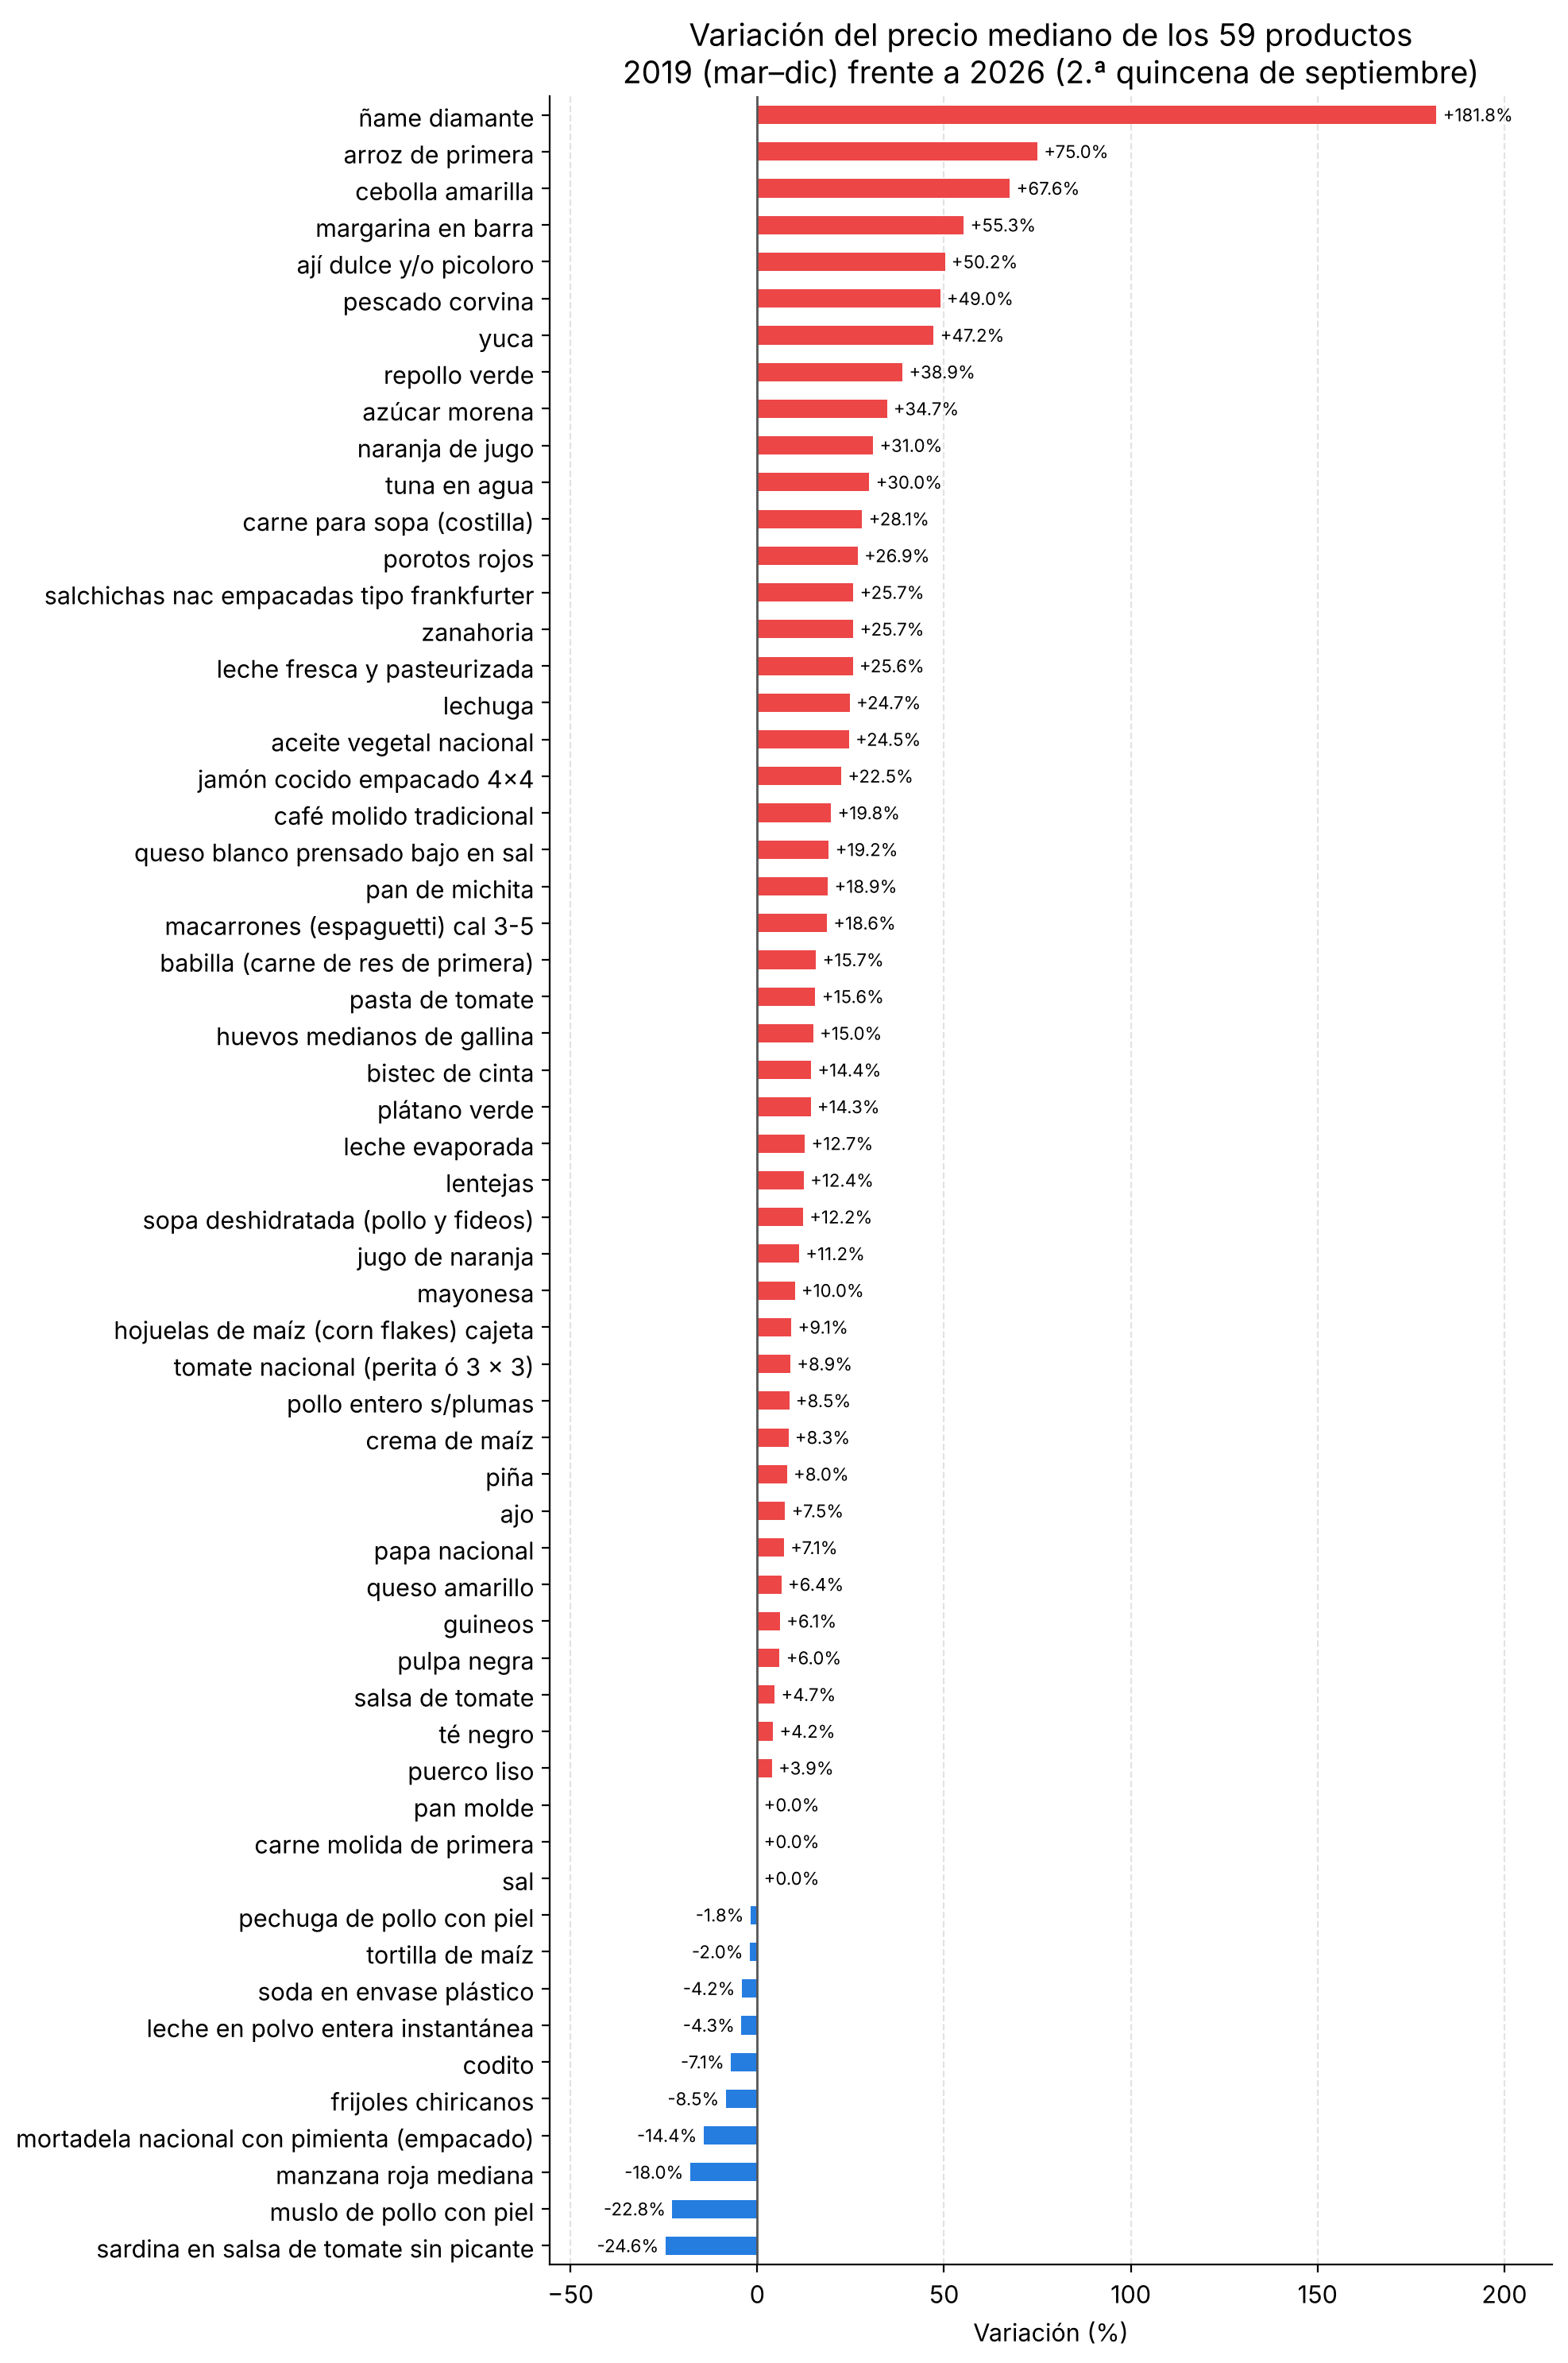

In [8]:
orden = productos['Cambio 2019→2026 (%)'].sort_values()
colores = []
for valor in orden:
    if valor > 0:
        colores.append(ROJO)
    else:
        colores.append(AZUL)

ax = orden.plot(kind='barh', figsize=(10, 15), color=colores)
plt.title('Variación del precio mediano de los 59 productos\n2019 (mar–dic) frente a 2026 (2.ª quincena de septiembre)')
plt.xlabel('Variación (%)')
plt.ylabel('')
plt.axvline(0, color='#555555', linewidth=1)
plt.grid(axis='x', linestyle='--', alpha=0.35)
ax.bar_label(ax.containers[0], fmt='%+.1f%%', padding=3, fontsize=8)
ax.margins(x=0.15)
plt.tight_layout()
plt.savefig(figuras / 'supermercados_variacion_59_productos.png', dpi=300, bbox_inches='tight')
plt.show()

## 6. Índice de precio relativo por tienda

Las tiendas no reportan los mismos productos, así que no se puede sumar su gasto. En cambio:

1. Para cada producto y mes se calcula la mediana entre tiendas (la "tienda típica").
2. Cada precio se divide entre esa mediana (precio relativo).
3. El índice de la tienda es la **media geométrica** de sus precios relativos × 100 (promedio de logaritmos y luego `exp`), para que un solo producto no domine.

100 = tienda típica; 110 = 10 % más cara; 90 = 10 % más barata. Solo tiendas con al menos 15 productos con precio.

In [9]:
limpios['log_relativo'] = (limpios['precio'] / limpios['mediana_mes']).apply(math.log)
indice_tienda = limpios.groupby(['anio', 'grupo', 'tienda']).agg(
    log_medio=('log_relativo', 'mean'),
    productos=('producto_estandar', 'nunique')).reset_index()
indice_tienda['indice'] = 100 * indice_tienda['log_medio'].apply(math.exp)
indice_tienda = indice_tienda[indice_tienda['productos'] >= 15].drop(columns='log_medio')
indice_tienda.round(1).to_csv(tablas / 'supermercados_indice_tienda.csv', index=False)

ranking_2026 = indice_tienda[(indice_tienda['anio'] == 2026) & (indice_tienda['productos'] >= 30)].sort_values('indice')
print('Tiendas con 30 productos o más en 2026:', len(ranking_2026))
display(pd.concat([ranking_2026.head(5), ranking_2026.tail(5)]).round(1))

Tiendas con 30 productos o más en 2026: 73


,anio,grupo,tienda,productos,indice
241,2026,Xtra,XTRA 24 DICIEMBRE,59,88.2
250,2026,Xtra,XTRA OJO DE AGUA,59,88.3
252,2026,Xtra,XTRA PAN DE AZÚCAR,59,88.3
245,2026,Xtra,XTRA EL LAGO,59,88.4
209,2026,Machetazo,EL MACHETAZO COSTA SUR,51,88.4
282,2026,minisúper,M/S YANET,33,125.8
258,2026,abarrotería,ABT. JUAN CARLOS,40,126.8
280,2026,minisúper,M/S PUEBLO NUEVO,33,127.0
286,2026,minisúper,MINISUPER GAO,34,127.6
266,2026,frutería,FRUTERÍA MIMI,35,137.9


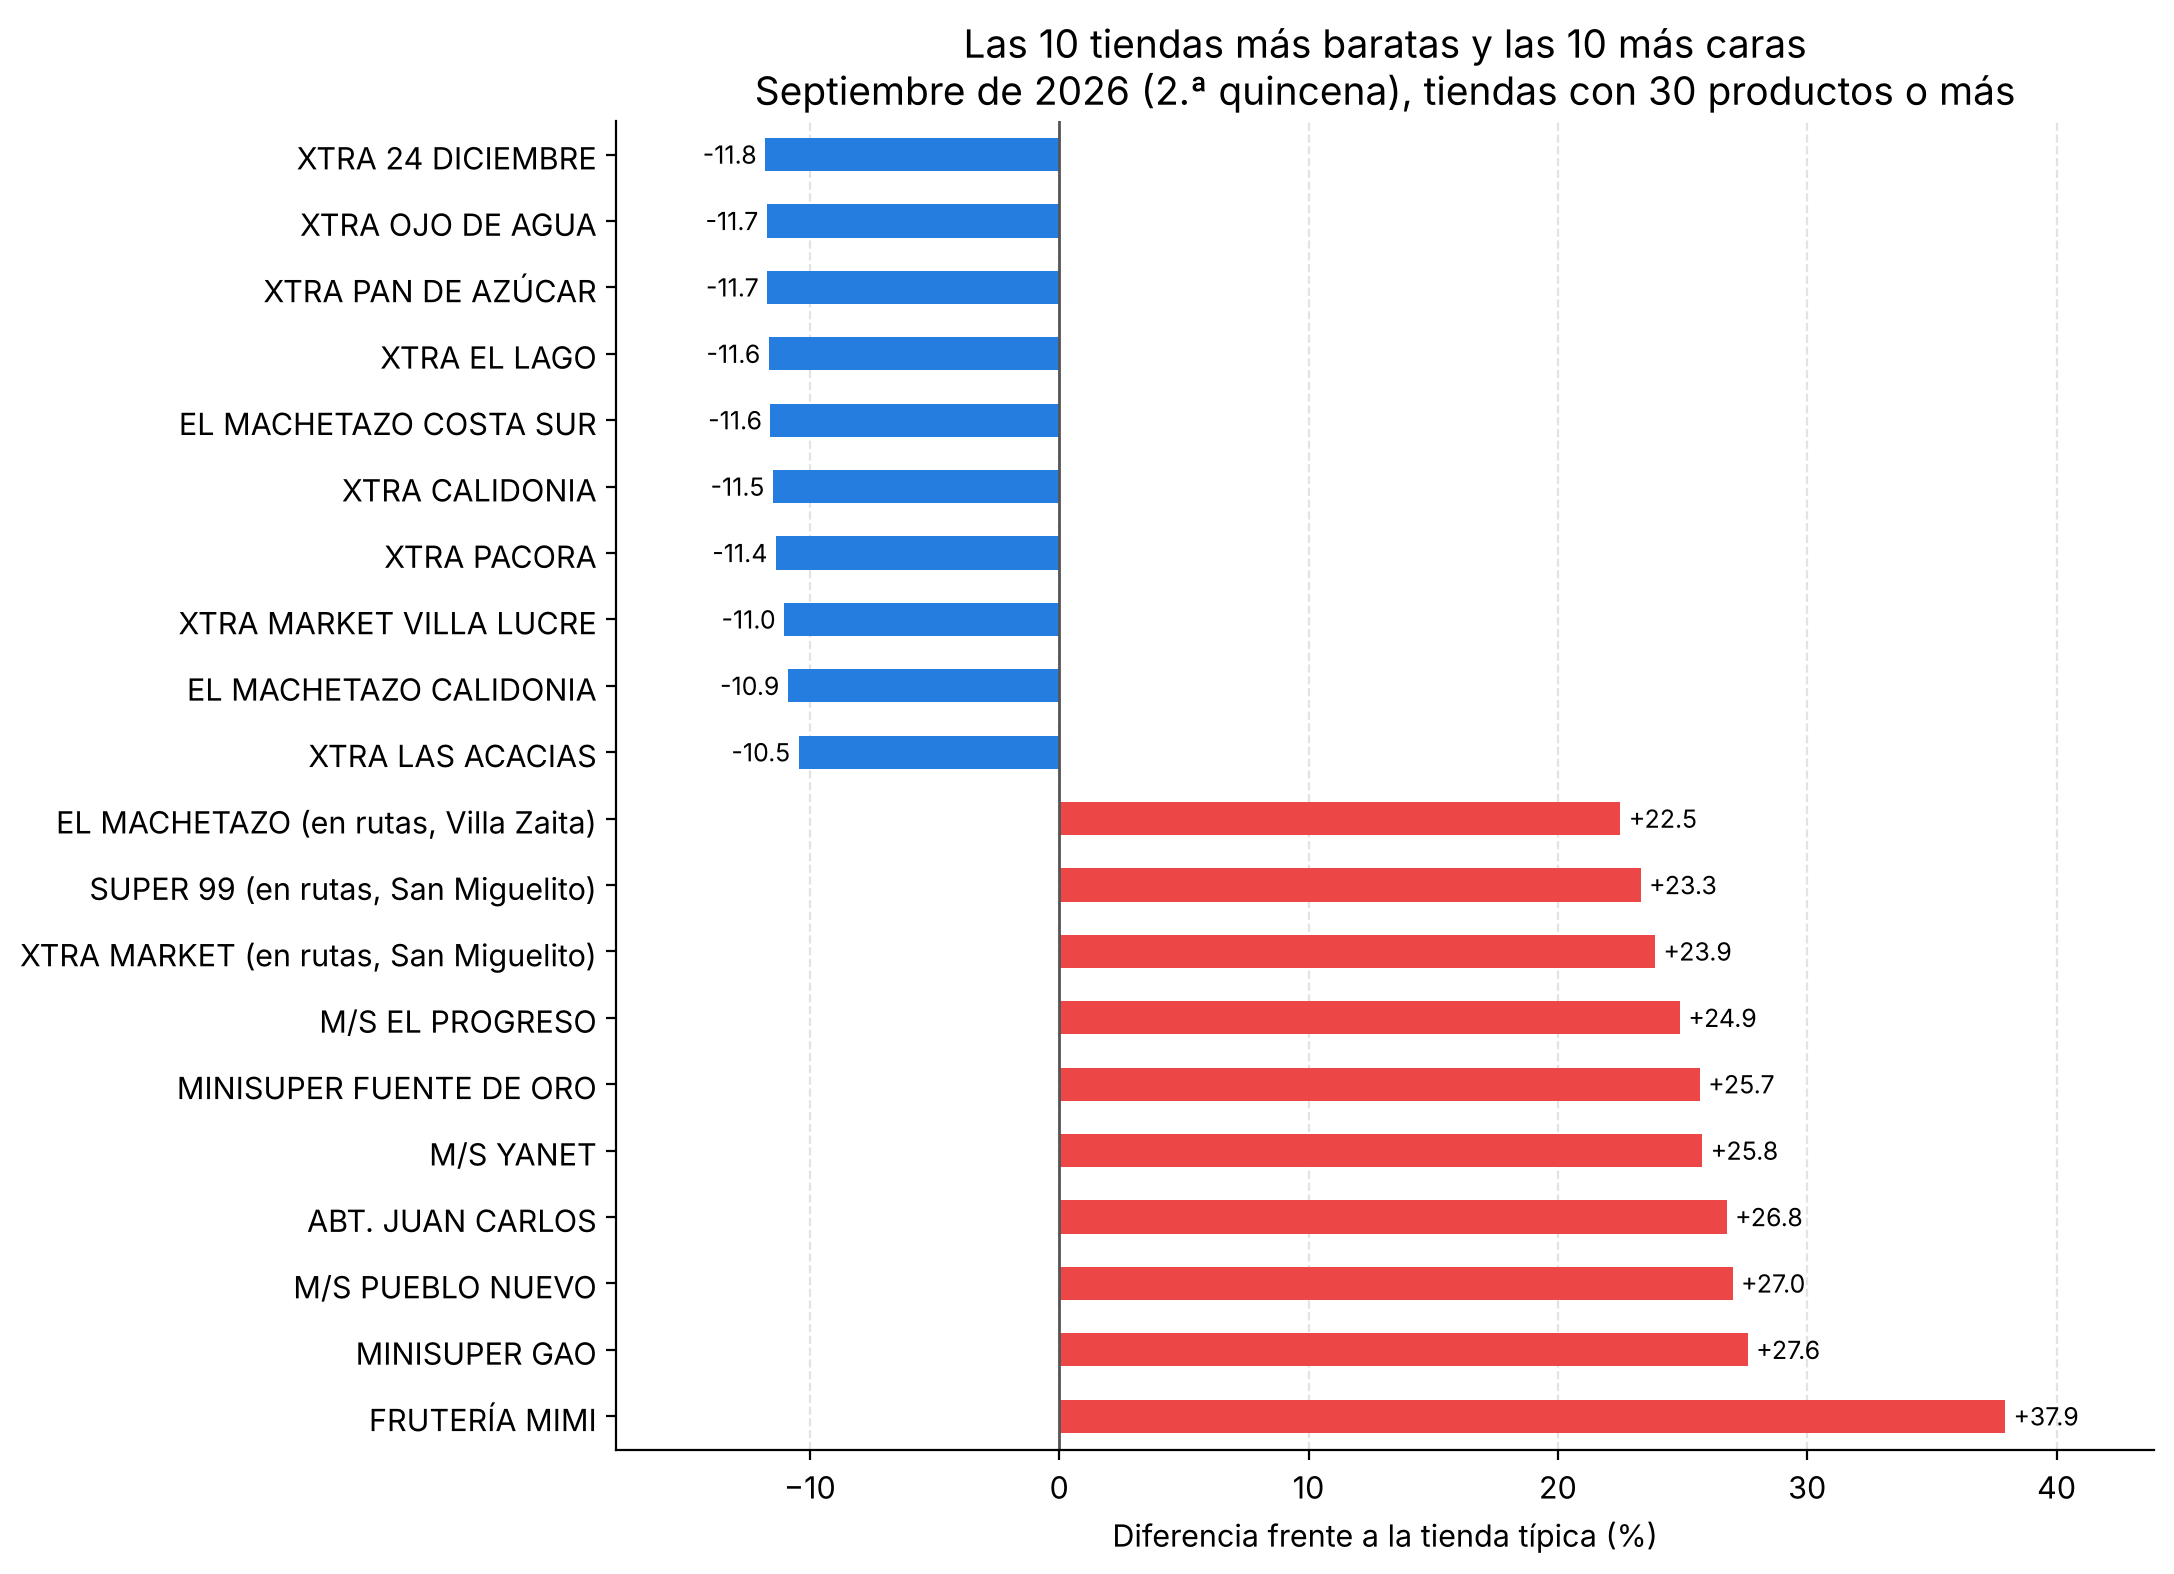

In [10]:
extremos = pd.concat([ranking_2026.head(10), ranking_2026.tail(10)])
extremos = extremos.sort_values('indice', ascending=False).set_index('tienda')
colores = []
for valor in extremos['indice']:
    if valor < 100:
        colores.append(AZUL)
    else:
        colores.append(ROJO)

# Se grafica índice - 100: cuánto más cara (+) o más barata (-) que la tienda típica.
ax = (extremos['indice'] - 100).plot(kind='barh', figsize=(11, 8), color=colores)
plt.title('Las 10 tiendas más baratas y las 10 más caras\nSeptiembre de 2026 (2.ª quincena), tiendas con 30 productos o más')
plt.xlabel('Diferencia frente a la tienda típica (%)')
plt.ylabel('')
plt.axvline(0, color='#555555', linewidth=1)
plt.grid(axis='x', linestyle='--', alpha=0.35)
ax.bar_label(ax.containers[0], fmt='%+.1f', padding=3, fontsize=9)
ax.margins(x=0.12)
plt.tight_layout()
plt.savefig(figuras / 'supermercados_ranking_tiendas_2026.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Índice por cadena comercial o tipo de tienda

El índice de una cadena es la **mediana** del índice de sus tiendas. Las tiendas sin cadena se agrupan por tipo. Se muestra el número de tiendas: un grupo con 1 a 3 tiendas (Riba Smith, El Fuerte, Casa de la Carne, frutería, cadena en rutas) es poco representativo y se interpreta con cuidado.

In [11]:
por_cadena = indice_tienda.pivot_table(index='grupo', columns='anio', values='indice', aggfunc='median')
n_tiendas = indice_tienda.pivot_table(index='grupo', columns='anio', values='tienda', aggfunc='count')
tabla_cadenas = por_cadena.round(1)
for anio in [2019, 2022, 2026]:
    tabla_cadenas['tiendas ' + str(anio)] = n_tiendas[anio]
tabla_cadenas = tabla_cadenas.sort_values(2026)
tabla_cadenas.to_csv(tablas / 'supermercados_indice_cadena.csv')
tabla_cadenas

anio,2019,2022,2026,tiendas 2019,tiendas 2022,tiendas 2026
grupo,,,,,,
Xtra,89.0,88.1,89.3,8.0,9.0,14.0
Machetazo,95.7,90.7,89.7,7.0,7.0,6.0
El Fuerte,90.4,91.8,96.0,2.0,3.0,3.0
Super 99,93.8,94.5,98.2,18.0,19.0,17.0
Rey,99.9,100.4,99.1,10.0,9.0,9.0
Riba Smith,115.1,112.5,106.2,2.0,2.0,2.0
abarrotería,111.7,117.5,113.9,12.0,16.0,8.0
minisúper,112.8,118.1,119.4,33.0,40.0,22.0
cadena en rutas,NaN,NaN,123.3,NaN,NaN,3.0


En la gráfica, cada barra muestra **cuánto más cara (+) o más barata (−)** es el grupo frente a la tienda típica y, al lado, el **costo estimado de la canasta** en ese grupo: costo oficial de junio × índice ÷ 100 (ver 7.1).

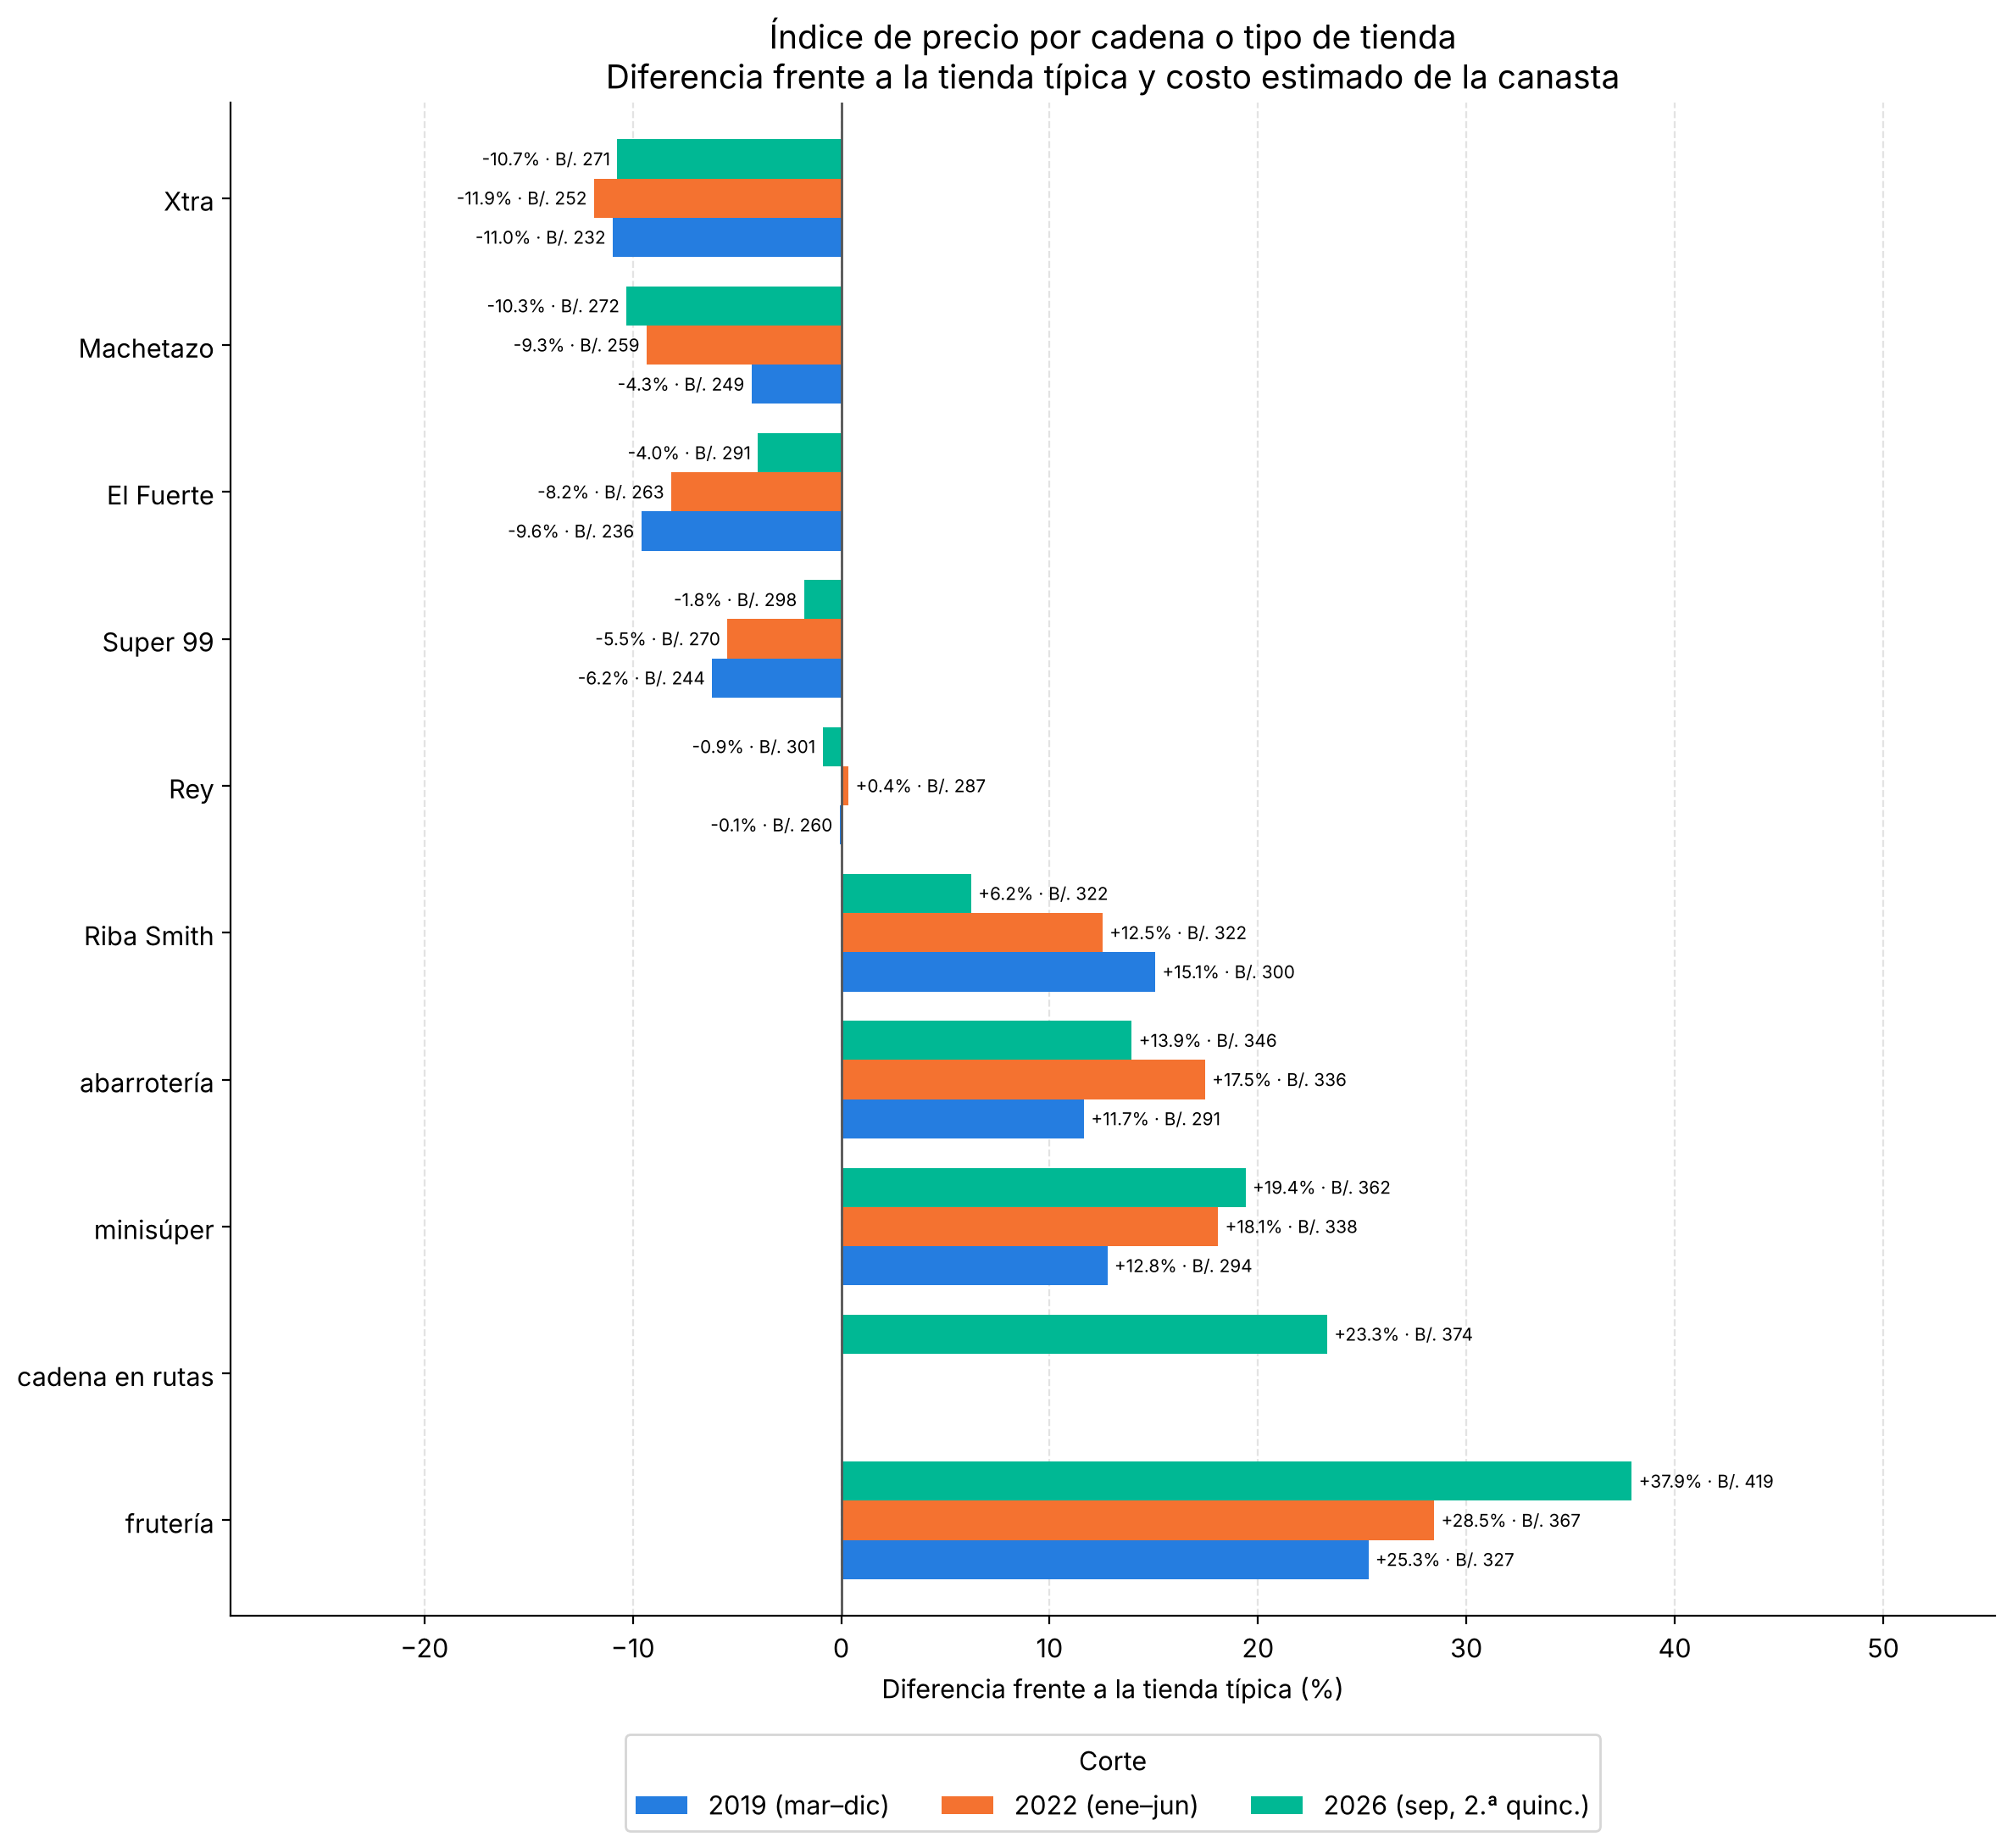

In [12]:
orden = por_cadena.dropna(subset=[2026]).sort_values(2026, ascending=False).index
diferencia = por_cadena.loc[orden, [2019, 2022, 2026]] - 100
estimado = por_cadena.loc[orden, [2019, 2022, 2026]] * costo_junio / 100

grafica = diferencia.copy()
grafica.columns = ['2019 (mar–dic)', '2022 (ene–jun)', '2026 (sep, 2.ª quinc.)']
ax = grafica.plot(kind='barh', figsize=(12, 11), width=0.8, color=['#257de0', '#f47230', '#00b894'])

# Etiqueta de cada barra: diferencia en % y costo estimado en B/.
for barras, anio in zip(ax.containers, [2019, 2022, 2026]):
    etiquetas = []
    for grupo in orden:
        if pd.isna(diferencia.loc[grupo, anio]):
            etiquetas.append('')
        else:
            etiquetas.append('%+.1f%% · B/. %.0f' % (diferencia.loc[grupo, anio], estimado.loc[grupo, anio]))
    ax.bar_label(barras, labels=etiquetas, padding=3, fontsize=7.5)

plt.title('Índice de precio por cadena o tipo de tienda\nDiferencia frente a la tienda típica y costo estimado de la canasta')
plt.xlabel('Diferencia frente a la tienda típica (%)')
plt.ylabel('')
plt.axvline(0, color='#555555', linewidth=1)
plt.grid(axis='x', linestyle='--', alpha=0.35)
ax.margins(x=0.35)
plt.legend(title='Corte', loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=3)
plt.tight_layout()
plt.savefig(figuras / 'supermercados_indice_cadenas.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.1. ¿Dónde rinde más la canasta? (costo estimado en B/.)

ACODECO no publica las cantidades de consumo de cada producto, así que no se puede calcular el costo exacto de la canasta en cada tienda. Se hace una **estimación**: costo oficial de ACODECO en junio de cada año (el mismo de la diapositiva de canasta vs. salario) × índice de la cadena ÷ 100. Ejemplo: una cadena con índice 90 pagaría ≈ 90 % del costo oficial. En 2026 el índice es de septiembre (2.ª quincena), porque es el único corte de precios por tienda.

anio,2019,2022,2026
Xtra,232.07,252.00,270.85
El Machetazo,249.42,259.23,272.20
Super 99,244.49,270.31,298.03
Rey,260.44,286.94,300.74
Riba Smith,299.92,321.77,322.38
Minisúper,293.93,337.64,362.34


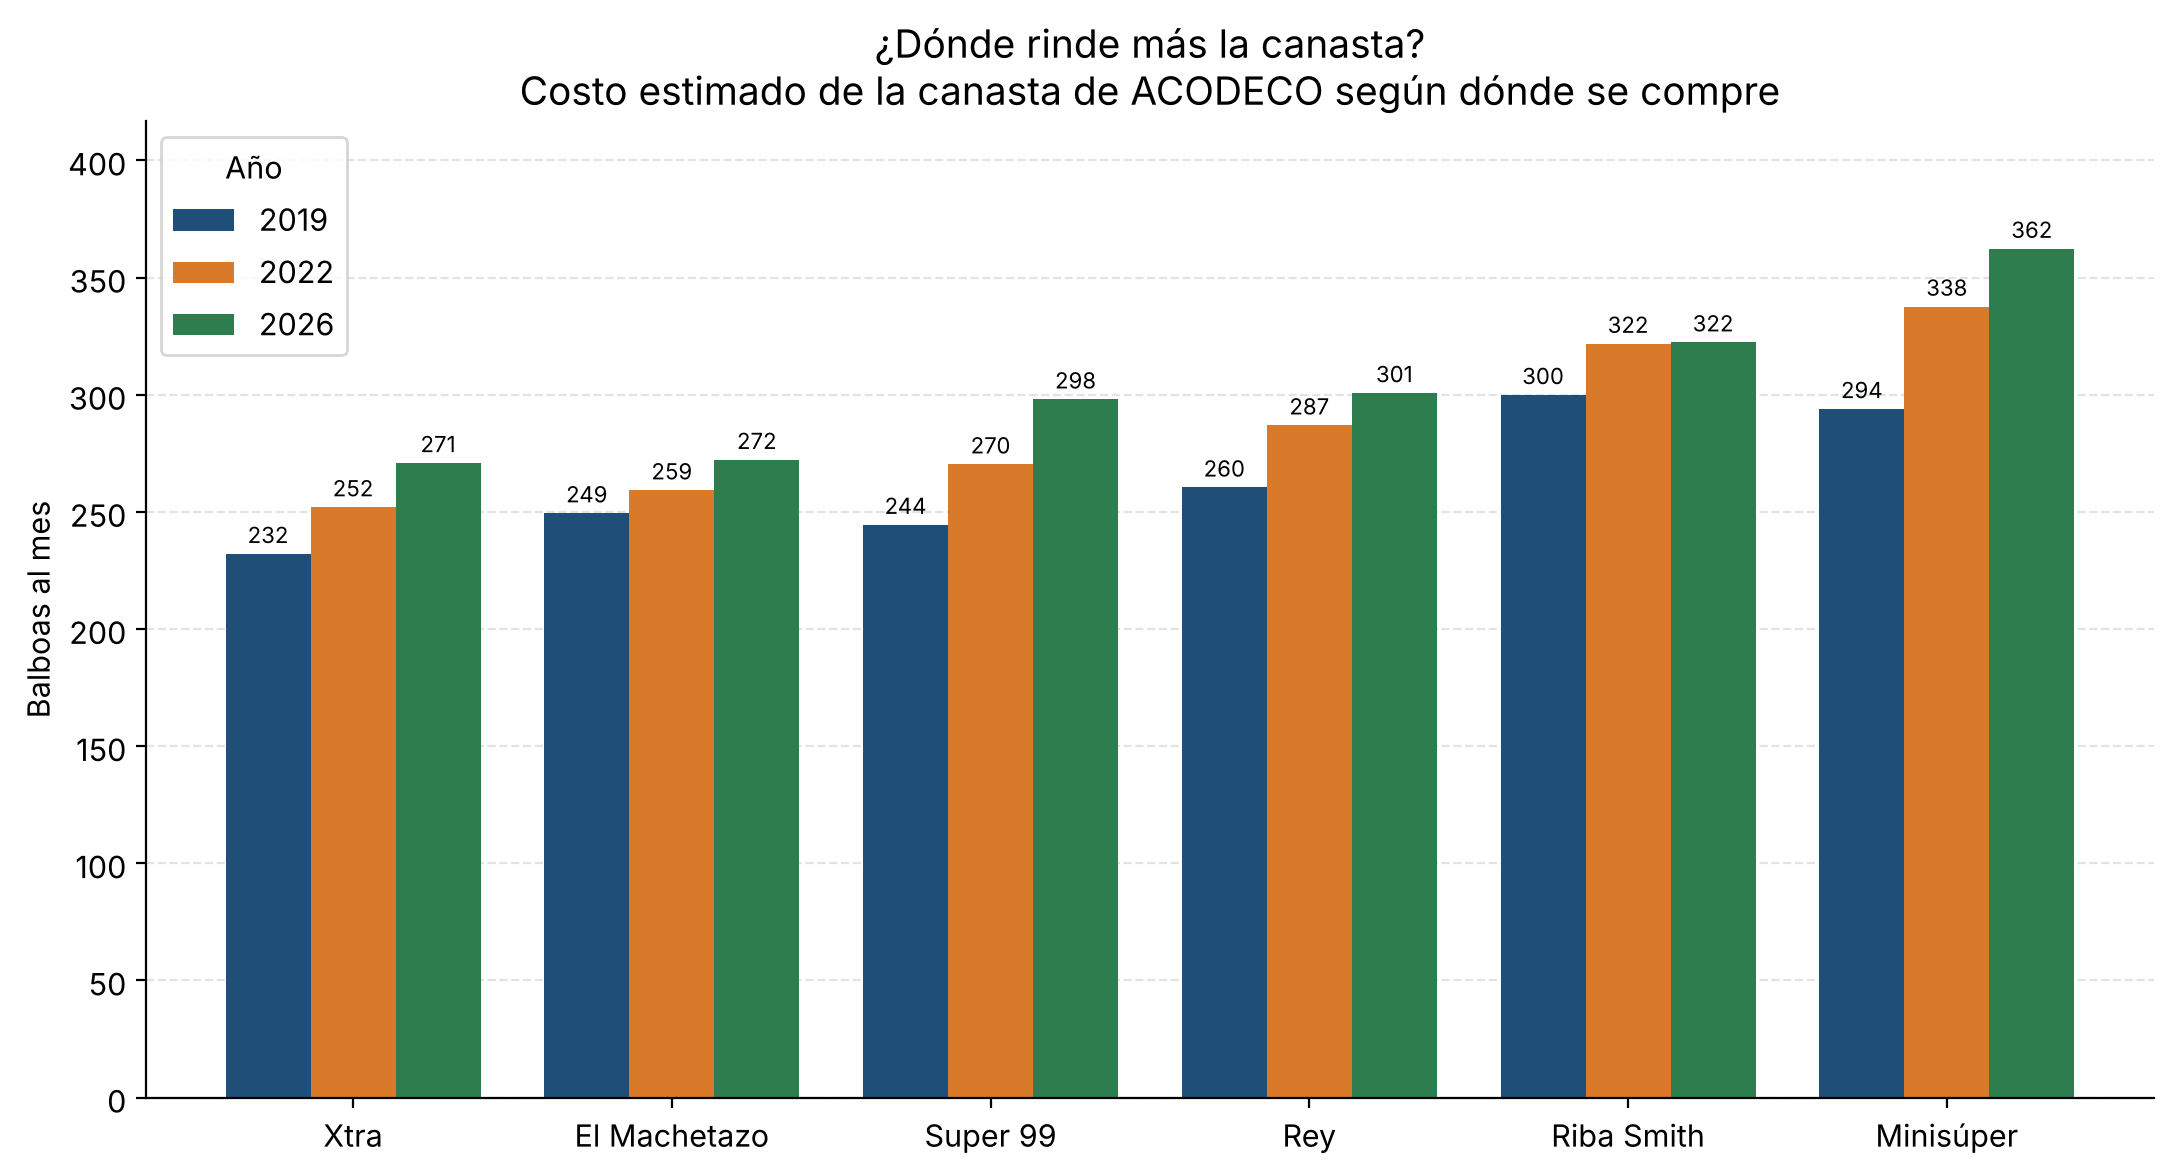

In [13]:
# costo_junio viene de la sección 4.
grupos = ['Xtra', 'Machetazo', 'Super 99', 'Rey', 'Riba Smith', 'minisúper']
costo_estimado = por_cadena.loc[grupos, [2019, 2022, 2026]] * costo_junio / 100
costo_estimado.index = ['Xtra', 'El Machetazo', 'Super 99', 'Rey', 'Riba Smith', 'Minisúper']
costo_estimado.round(2).to_csv(tablas / 'supermercados_costo_estimado.csv')
display(costo_estimado.round(2))

ax = costo_estimado.plot(kind='bar', figsize=(11, 6), width=0.8,
                         color=['#1f4e79', '#d97a2b', '#2e7d4f'])
plt.title('¿Dónde rinde más la canasta?\nCosto estimado de la canasta de ACODECO según dónde se compre')
plt.xlabel('')
plt.ylabel('Balboas al mes')
plt.xticks(rotation=0)
plt.ylim(0, costo_estimado.max().max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.35)
for barras in ax.containers:
    ax.bar_label(barras, fmt='%.0f', padding=2, fontsize=8)
plt.legend(['2019', '2022', '2026'], title='Año', loc='upper left')
plt.tight_layout()
plt.savefig(figuras / 'supermercados_costo_estimado.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Precio relativo de cada producto por cadena (2026)

En qué productos es barata o cara cada cadena. Cada celda es la mediana, entre las tiendas de la cadena, de *precio / mediana del producto × 100*. Menos de 100 = más barata que la tienda típica. Celda vacía = no lo reportó.

In [14]:
cortes_2026 = limpios[limpios['anio'] == 2026].copy()
cortes_2026['relativo'] = cortes_2026['precio'] / cortes_2026['mediana_mes'] * 100
matriz = cortes_2026.pivot_table(index='producto_estandar', columns='grupo', values='relativo', aggfunc='median')
matriz = matriz[por_cadena[2026].dropna().sort_values().index]
matriz.round(0).to_csv(tablas / 'supermercados_producto_por_cadena_2026.csv')

resumen = pd.DataFrame({'productos por debajo de 100': (matriz < 100).sum(),
                        'productos reportados': matriz.notna().sum()})
display(resumen)
with pd.option_context('display.max_rows', None):
    display(matriz.round(0))

,productos por debajo de 100,productos reportados
grupo,,
Xtra,51,59
Machetazo,43,54
El Fuerte,33,56
Super 99,20,56
Rey,31,58
Riba Smith,17,53
abarrotería,6,49
minisúper,3,51
cadena en rutas,2,46


grupo,Xtra,Machetazo,El Fuerte,Super 99,Rey,Riba Smith,abarrotería,minisúper,cadena en rutas,frutería
producto_estandar,,,,,,,,,,
aceite vegetal nacional,79.0,85.0,119.0,94.0,100.0,110.0,110.0,110.0,110.0,110.0
ajo,98.0,NaN,69.0,101.0,93.0,71.0,NaN,113.0,174.0,NaN
ají dulce y/o picoloro,58.0,55.0,60.0,116.0,112.0,117.0,97.0,97.0,97.0,127.0
arroz de primera,109.0,NaN,100.0,100.0,93.0,NaN,118.0,114.0,114.0,NaN
azúcar morena,98.0,92.0,107.0,84.0,97.0,92.0,115.0,115.0,115.0,131.0
babilla (carne de res de primera),98.0,102.0,104.0,NaN,99.0,94.0,NaN,88.0,NaN,NaN
bistec de cinta,98.0,95.0,109.0,96.0,101.0,96.0,108.0,118.0,112.0,NaN
café molido tradicional,80.0,93.0,150.0,65.0,100.0,124.0,151.0,141.0,149.0,164.0
carne molida de primera,100.0,100.0,100.0,100.0,100.0,100.0,101.0,100.0,179.0,NaN


## 9. Dispersión de precios entre tiendas (2026)

Para cada producto se reportan el precio mínimo, la mediana, el máximo y el cociente máximo/mínimo: cuánto puede ahorrar quien compara.

In [15]:
dispersion = cortes_2026.groupby('producto_estandar')['precio'].agg(['count', 'min', 'median', 'max'])
dispersion['max/min'] = dispersion['max'] / dispersion['min']
mas_barata = cortes_2026.loc[cortes_2026.groupby('producto_estandar')['precio'].idxmin()]
dispersion['más barato en'] = mas_barata.set_index('producto_estandar')['tienda']
dispersion['grupo más barato'] = mas_barata.set_index('producto_estandar')['grupo']
dispersion = dispersion.sort_values('max/min', ascending=False)
dispersion.round(2).to_csv(tablas / 'supermercados_dispersion_2026.csv')

print('Productos con máximo >= 2 veces el mínimo:', (dispersion['max/min'] >= 2).sum(), 'de', len(dispersion))
print('Grupo con el precio más bajo (primera tienda en caso de empate):')
display(dispersion['grupo más barato'].value_counts())
with pd.option_context('display.max_rows', None):
    display(dispersion.round(2))

Productos con máximo >= 2 veces el mínimo: 31 de 59
Grupo con el precio más bajo (primera tienda en caso de empate):


grupo más barato
Xtra           31
Super 99        8
Machetazo       8
El Fuerte       4
minisúper       3
abarrotería     2
Rey             2
Riba Smith      1
Name: count, dtype: int64

,count,min,median,max,max/min,más barato en,grupo más barato
producto_estandar,,,,,,,
cebolla amarilla,82,1.09,2.95,4.41,4.05,M/S MULTI CARNES,minisúper
yuca,30,0.55,1.06,2.09,3.80,XTRA MARKET VILLA LUCRE,Xtra
lentejas,82,1.17,1.81,4.08,3.49,XTRA CHEPO,Xtra
café molido tradicional,72,2.62,4.85,8.25,3.15,XTRA LAS ACACIAS,Xtra
lechuga,70,1.96,3.73,6.06,3.09,XTRA 24 DICIEMBRE,Xtra
muslo de pollo con piel,52,1.47,2.84,4.46,3.03,SUPER 99 MAÑANITAS,Super 99
naranja de jugo,32,0.58,1.04,1.75,3.02,SUPER 99 LA CABIMA,Super 99
margarina en barra,79,2.98,4.41,8.82,2.96,EL MACHETAZO NVO. TOCUMEN,Machetazo
tomate nacional (perita ó 3 x 3),76,1.52,2.95,4.41,2.90,ABT. LA PAGODA NO. 2,abarrotería


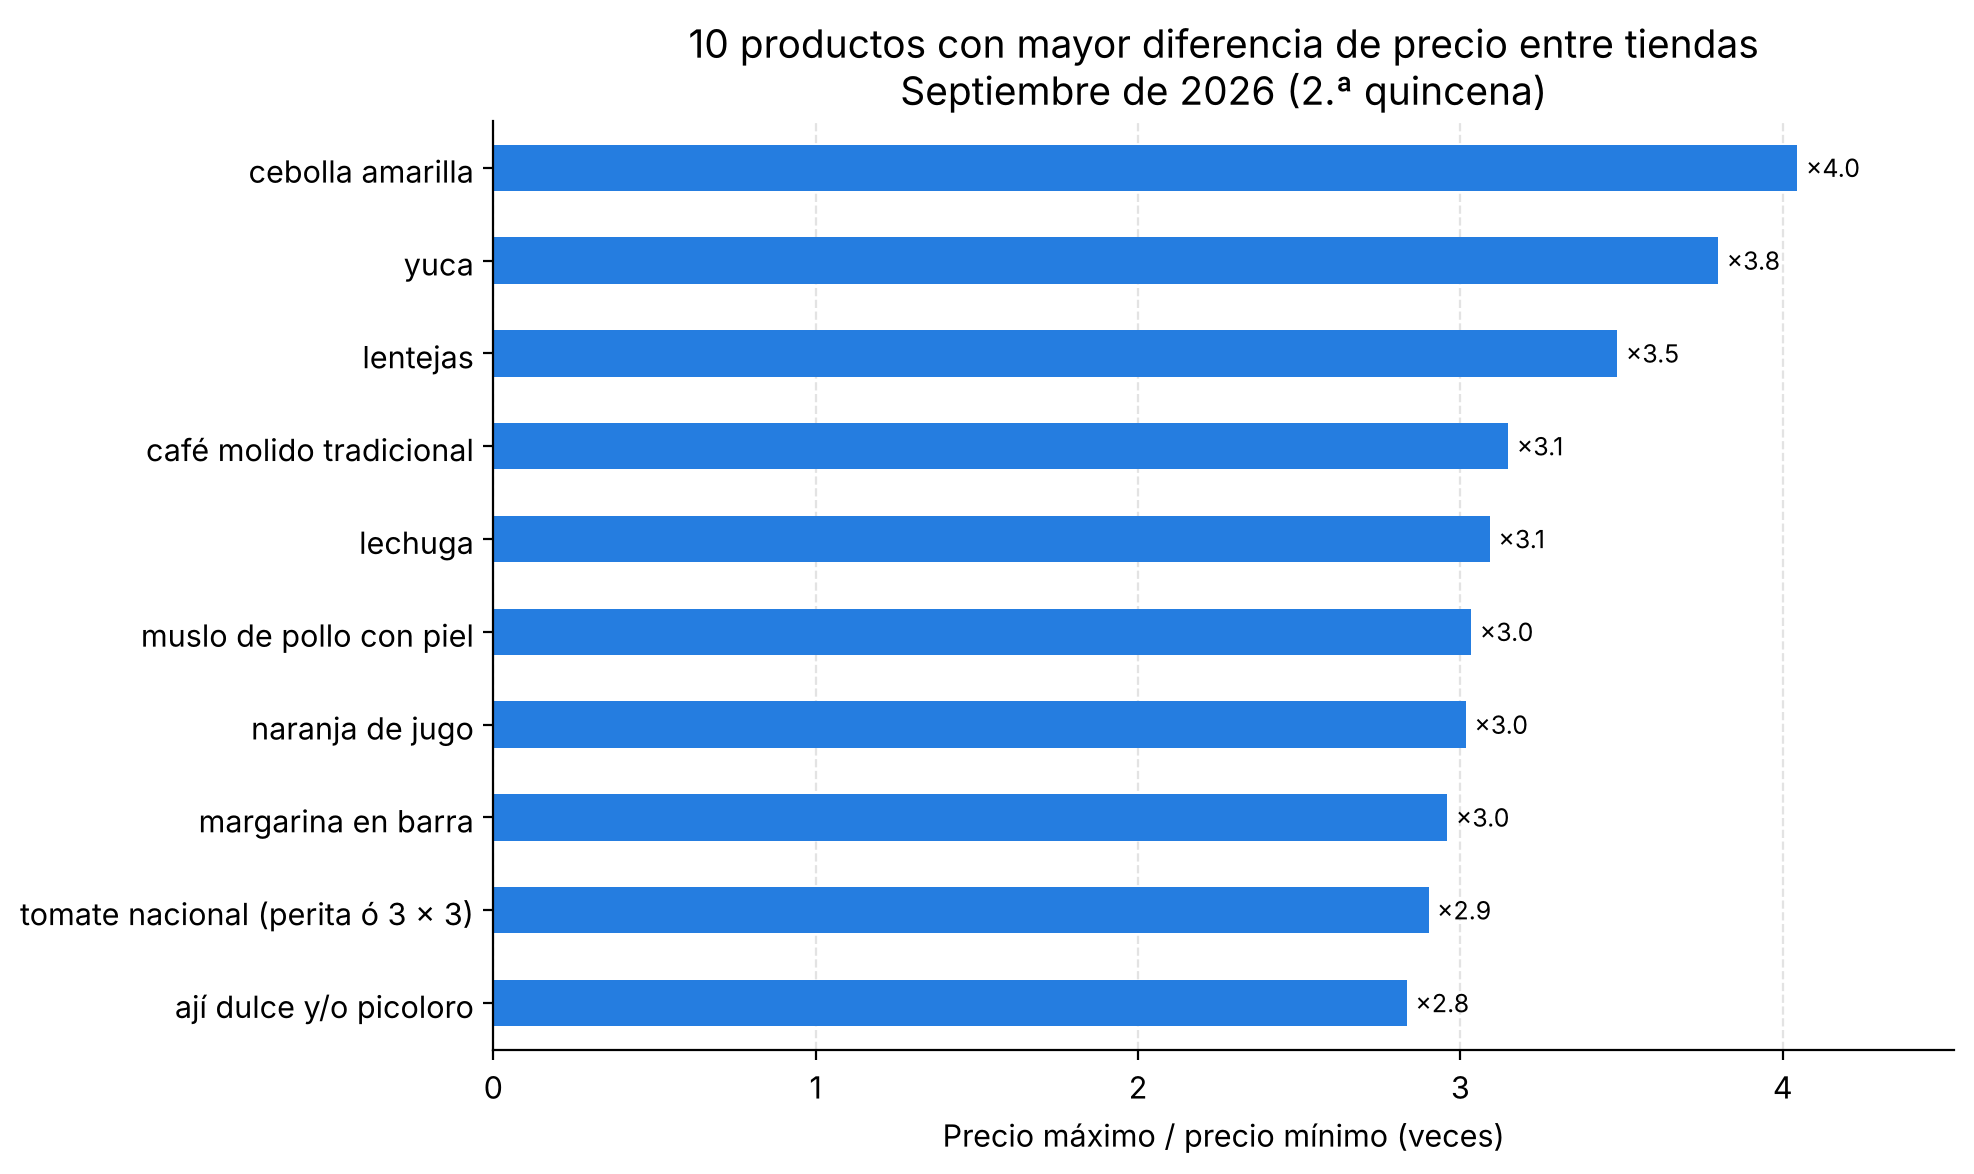

In [16]:
top = dispersion['max/min'].head(10).sort_values()
ax = top.plot(kind='barh', figsize=(10, 6), color=AZUL)
plt.title('10 productos con mayor diferencia de precio entre tiendas\nSeptiembre de 2026 (2.ª quincena)')
plt.xlabel('Precio máximo / precio mínimo (veces)')
plt.ylabel('')
plt.grid(axis='x', linestyle='--', alpha=0.35)
ax.bar_label(ax.containers[0], fmt='×%.1f', padding=3, fontsize=9)
ax.margins(x=0.12)
plt.tight_layout()
plt.savefig(figuras / 'supermercados_dispersion_2026.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. San Miguelito frente al resto (solo cadenas)

Se comparan solo supermercados de cadena, para no mezclar el efecto zona con el efecto tipo de tienda. El grupo "resto" son tiendas sin zona confirmada (en su mayoría de la ciudad de Panamá), no "la capital". En 2019 y 2022 hay muy pocas tiendas de San Miguelito identificadas, así que la comparación solo es informativa en 2026.

In [17]:
zona_tienda = limpios.groupby(['anio', 'tienda'])['zona'].first().reset_index()
cadenas_grandes = ['Super 99', 'Rey', 'Xtra', 'Machetazo', 'Riba Smith', 'El Fuerte']
por_zona = indice_tienda[indice_tienda['grupo'].isin(cadenas_grandes)].merge(zona_tienda, on=['anio', 'tienda'])
por_zona['zona'] = por_zona['zona'].replace({'sin_clasificar': 'resto', 'san_miguelito': 'San Miguelito'})
por_zona.groupby(['anio', 'zona'])['indice'].agg(tiendas='count', indice_mediano='median').round(1).unstack()

tiendas       indice_mediano      
zona San Miguelito resto  San Miguelito resto
anio                                         
2019             2    45           92.5  94.2
2022             2    47           91.2  94.3
2026             9    42           96.5  96.0

## 11. Conclusiones

*Redactar después de ejecutar, citando solo cifras que aparecen arriba.* Guía:

1. **Cadenas (sección 7):** qué grupos quedan por debajo y por encima de 100 en los tres cortes, y si la brecha minisúper/abarrotería frente a las cadenas creció.
2. **Productos (sección 5):** cuántos de los 59 suben, la variación mediana y si se sostiene con las mismas tiendas y septiembre contra septiembre; cuáles suben y bajan más y en qué tramo (2019→2022 o 2022→2026).
3. **Dispersión (sección 9):** en cuántos productos el máximo duplica el mínimo y qué cadena tiene más veces el precio más bajo.
4. **Limitaciones:** cortes no homogéneos (2026 es una quincena), muestra de tiendas cambiante, índice relativo (no es costo de canasta), errores de captura en la fuente y cobertura solo de Panamá y San Miguelito.